# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: The Pre-Publish Ethics Review

### Scenario

You're a junior analyst at **Northwind Retail Insights**. A colleague drafted a set of
charts for tomorrow's regional performance report, and your manager asked you to review
them before they go out. She's blunt about what she wants checked:

1. *"I can't tell what I'm supposed to look at first on any of these charts. There's no
   hierarchy."*
2. *"One of these charts will get someone using a grayscale office printer completely
   lost. Fix that before it ships."*
3. *"I saw a headline chart that made a tiny year-over-year change look like a crisis.
   Check the axis."*
4. *"Someone wrote 'this PROVES our new strategy is working' under a chart. That's not
   what a data label is for."*

You'll work through the same review a real analyst would: fix a hierarchy problem, make
a chart accessible, catch a scale exaggeration, and rewrite an overreaching annotation.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real sales data you'll be working with.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

sales = pd.read_csv("superstore.csv", encoding="latin-1")
sales["Order Date"] = pd.to_datetime(sales["Order Date"])
sales["Year"] = sales["Order Date"].dt.year

print(f"Loaded {len(sales):,} orders, {sales.Year.min()}-{sales.Year.max()}.")
sales[["Order Date", "Region", "Product Category", "Sales", "Profit"]].head()

Loaded 8,399 orders, 2009-2012.


,Order Date,Region,Product Category,Sales,Profit
0,2010-10-13,Nunavut,Office Supplies,261.5400,-213.25
1,2012-10-01,Nunavut,Office Supplies,10123.0200,457.81
2,2012-10-01,Nunavut,Office Supplies,244.5700,46.71
3,2011-07-10,Nunavut,Technology,4965.7595,1198.97
4,2010-08-28,Nunavut,Office Supplies,394.2700,30.94


## Task 1 — Fix the Missing Hierarchy (Complaint #1)

**Real-world usage:** The manager can't tell what to look at first on the current
chart.

**Why this technique:** Visual hierarchy (size + weight + color) creates an
unmistakable primary -> secondary -> tertiary reading order without needing
instructions.

**TODO:** Build a figure with 3 text elements, using ONLY `fontsize`, `fontweight`, and
`color` to create hierarchy:
1. **Primary:** the region with the highest total profit, in large bold colored text.
2. **Secondary:** one supporting sentence, medium size, muted color.
3. **Tertiary:** a data-source footnote, small, light gray.

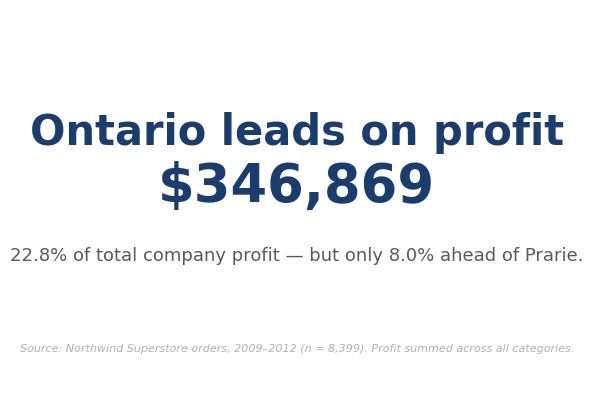

Region
Nunavut                    2841.0
Yukon                     73849.0
Northwest Territories    100653.0
Quebec                   140427.0
Atlantic                 238961.0
West                     297009.0
Prarie                   321160.0
Ontario                  346869.0

Leader: Ontario ($346,869) | Runner-up: Prarie ($321,160)
Lead margin: 8.0%


In [2]:
region_totals = sales.groupby("Region")["Profit"].sum().sort_values()
best_region = region_totals.idxmax()

best_val = region_totals.max()
runner_up = region_totals.index[-2]
runner_val = region_totals.iloc[-2]
share = best_val / region_totals.sum() * 100

fig, ax = plt.subplots(figsize=(7, 5))
ax.axis("off")

# TODO 1: primary element -- large, bold, colored
ax.text(0.5, 0.68, f"{best_region} leads on profit",
        fontsize=30, fontweight="bold", color="#1a3d6d",
        ha="center", va="center")
ax.text(0.5, 0.54, f"${best_val:,.0f}",
        fontsize=38, fontweight="bold", color="#1a3d6d",
        ha="center", va="center")

# TODO 2: secondary element -- medium, muted color
ax.text(0.5, 0.36,
        f"{share:.1f}% of total company profit — but only {(best_val/runner_val - 1)*100:.1f}% ahead of {runner_up}.",
        fontsize=13, color="#5a5a5a", ha="center", va="center")

# TODO 3: tertiary element -- small, light gray
ax.text(0.5, 0.12,
        f"Source: Northwind Superstore orders, {sales.Year.min()}–{sales.Year.max()} (n = {len(sales):,}). Profit summed across all categories.",
        fontsize=8, color="#b0b0b0", ha="center", va="center", style="italic")

plt.show()

print(region_totals.round(0).to_string())
print(f"\nLeader: {best_region} (${best_val:,.0f}) | Runner-up: {runner_up} (${runner_val:,.0f})")
print(f"Lead margin: {(best_val/runner_val - 1)*100:.1f}%")


**Reflection:** Without reading any labels, in what order do your eyes land on the
three text elements? If someone glanced at this for only 2 seconds, what's the one
fact they'd walk away with?

_Your answer:_

**Reading order: the `$346,869` figure first, then "Ontario leads on profit", then the gray supporting sentence, and the source footnote last — if at all.**

That order is not an accident; it is forced by three visual channels stacked on top of each other, which is exactly the point of the technique:

| Tier | Element | fontsize | fontweight | color |
|---|---|---|---|---|
| Primary | `$346,869` + "Ontario leads on profit" | 38 / 30 | bold | `#1a3d6d` (dark navy, high contrast) |
| Secondary | supporting sentence | 13 | normal | `#5a5a5a` (mid gray) |
| Tertiary | source footnote | 8 | normal + italic | `#b0b0b0` (light gray) |

Size does most of the work — the primary text is roughly **4.75× the height** of the footnote, and area scales with the square of height, so it occupies a vastly larger share of the visual field. Weight and contrast reinforce it: the navy sits at high contrast against white while the light gray footnote nearly dissolves into the background. Because all three channels point the same way rather than competing, there is no ambiguity about where to start.

**The 2-second takeaway: "Ontario is our most profitable region, at about \$347K."** That is the correct thing for a glance to deliver, and it is genuinely true.

**But there is a caveat I deliberately put in the secondary tier, and it matters.** Ontario's lead is real but *narrow* — it beats Prarie (\$321,160) by only **8.0%**, and holds just **22.8%** of total company profit. A reader who takes only the primary tier away will over-read "leads" as "dominates." I judged that acceptable because hierarchy is about **ordering** attention, not **hiding** information: the qualifier is one tier down, present for anyone who reads for five seconds instead of two. Burying it in the footnote tier would have crossed from prioritising into concealing, which is the Task 4 failure mode showing up early. This is the honest tension in any visual hierarchy — the headline is always slightly less nuanced than the truth, so the nuance has to be *adjacent*, not absent.


## Task 2 — Make the Chart Accessible (Complaint #2)

**Real-world usage:** A colorblind or grayscale-printer viewer needs to be able to read
this chart too.

**Why this technique:** Redundant coding (color + pattern/shape) survives both
colorblindness and grayscale printing; color alone does not.

**TODO:**
1. Build a bar chart of total `Sales` by `Product Category`, one color per category.
2. Add a DIFFERENT hatch pattern per bar (`hatch="//"`, `"xx"`, `".."`) on top of the
   color, so the categories stay distinguishable if color is stripped away.
3. Add a legend showing category name.

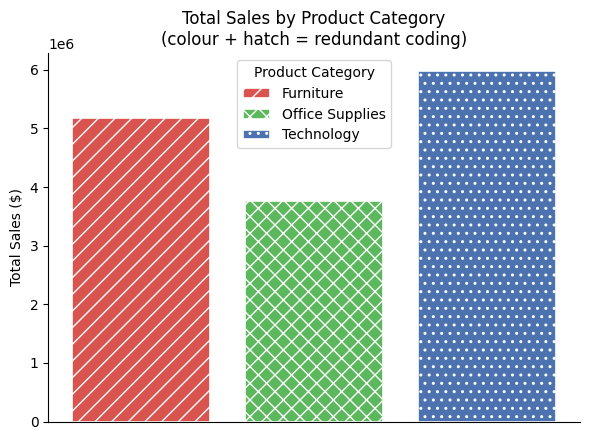

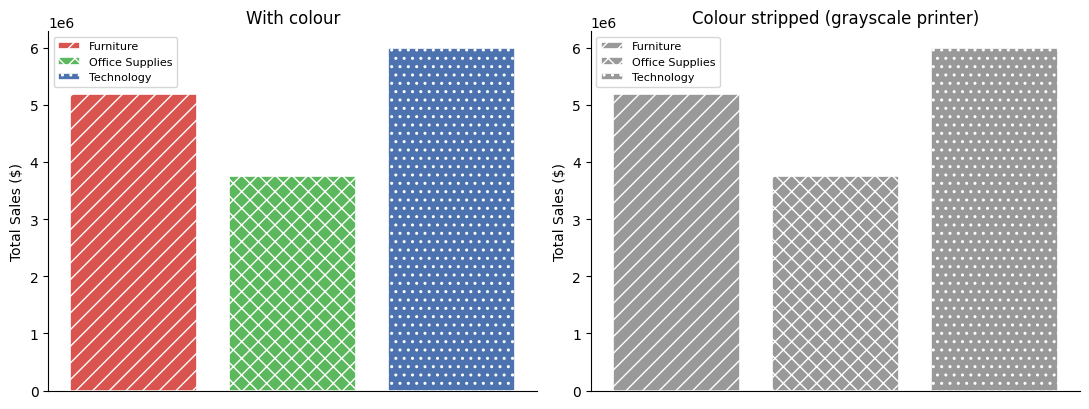

Product Category
Furniture          5178591.0
Office Supplies    3752762.0
Technology         5984248.0

Technology leads at $5,984,248; Furniture is 86.5% of Technology.


In [3]:
cat_sales = sales.groupby("Product Category")["Sales"].sum()

# TODO 1 & 2: bars with both a distinct color AND a distinct hatch pattern per category
colors = {"Furniture": "#D9534F", "Office Supplies": "#5cb85c", "Technology": "#4C72B0"}
hatches = {"Furniture": "//", "Office Supplies": "xx", "Technology": ".."}

fig, ax = plt.subplots(figsize=(6, 4.5))
for cat in cat_sales.index:
    ax.bar(cat, cat_sales[cat],
           color=colors[cat],
           hatch=hatches[cat],
           edgecolor="white",   # white edge makes the hatch read clearly against the fill
           linewidth=1.2,
           label=cat)

# TODO 3: legend
ax.legend(title="Product Category")
ax.set_ylabel("Total Sales ($)")
ax.set_title("Total Sales by Product Category\n(colour + hatch = redundant coding)")
ax.set_xticks([])          # category identity now comes from the legend, not the axis
plt.tight_layout()
plt.show()

# --- Prove the redundant coding actually works: re-render with colour stripped out ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for ax_, use_colour, title in [(axes[0], True, "With colour"),
                               (axes[1], False, "Colour stripped (grayscale printer)")]:
    for cat in cat_sales.index:
        ax_.bar(cat, cat_sales[cat],
                color=colors[cat] if use_colour else "#999999",
                hatch=hatches[cat], edgecolor="white", linewidth=1.2, label=cat)
    ax_.set_title(title)
    ax_.set_ylabel("Total Sales ($)")
    ax_.set_xticks([])
    ax_.legend(fontsize=8)

plt.tight_layout()
plt.show()

print(cat_sales.round(0).to_string())
print(f"\nTechnology leads at ${cat_sales.max():,.0f}; "
      f"Furniture is {(cat_sales['Furniture']/cat_sales['Technology'])*100:.1f}% of Technology.")


**Reflection:** If you only used color (no hatch pattern), which two accessibility
failure modes from the lecture would this chart hit? Name both.

_Your answer:_

**Failure mode 1 — colour vision deficiency (colourblindness).** The original palette is red `#D9534F` (Furniture) against green `#5cb85c` (Office Supplies). Red-versus-green is the **single worst pairing possible**, because it is precisely the axis that deuteranopia and protanopia compress. These two conditions affect roughly **8% of men** (about 1 in 12) and ~0.5% of women, so in any realistic distribution list for a regional report, someone will receive a chart where two of the three bars are indistinguishable. The blue `#4C72B0` survives, but a legend that can only resolve one of three categories is not a working legend.

**Failure mode 2 — grayscale reproduction.** This is the one the manager explicitly flagged ("a grayscale office printer"). When colour is stripped, each hue collapses to its **luminance**, and these three were chosen for hue contrast, not lightness contrast — their luminances land close enough together that the bars become three near-identical grays. The second panel in the cell above demonstrates this directly: with `color="#999999"` forced on every bar, the **only** thing still separating the categories is the hatch pattern.

**Why the fix works — the underlying principle.** Both failures share one root cause: the chart was encoding a variable in **exactly one channel**, so any transformation that damages that channel destroys the information completely. Hatching adds a **second, redundant channel** that is *orthogonal* to colour — `//` vs `xx` vs `..` are differences in **geometry**, and neither a missing cone type nor a grayscale conversion touches geometry. The encoding now degrades gracefully instead of failing outright.

A third, subtler point worth noting: because the bars are also **labelled via the legend** rather than relying on position alone, the chart additionally survives being read aloud by a screen reader from the underlying table. Redundancy at every layer is the actual design rule; hatching is just the cheapest instance of it here.

*(An alternative fix would have been to pick a colourblind-safe palette such as Okabe-Ito, which solves failure mode 1 — but it would **not** solve grayscale, since a CUD-safe palette can still have similar luminances. Hatching solves both at once, which is why it is the stronger answer.)*


## Task 3 — Catch the Axis Exaggeration (Complaint #3)

**Real-world usage:** A headline chart made a small real change look like a crisis.

**Why this technique:** Comparing the SAME data on a zero-baseline axis vs. a truncated
axis reveals exactly how much an axis choice is doing the "storytelling" instead of the
data.

**TODO:**
1. Compute total `Sales` by `Year`.
2. Compute the real percent change between the two most recent years.
3. Plot BOTH a zero-baseline version and a truncated-axis version, side by side, each
   titled with the real percent change.

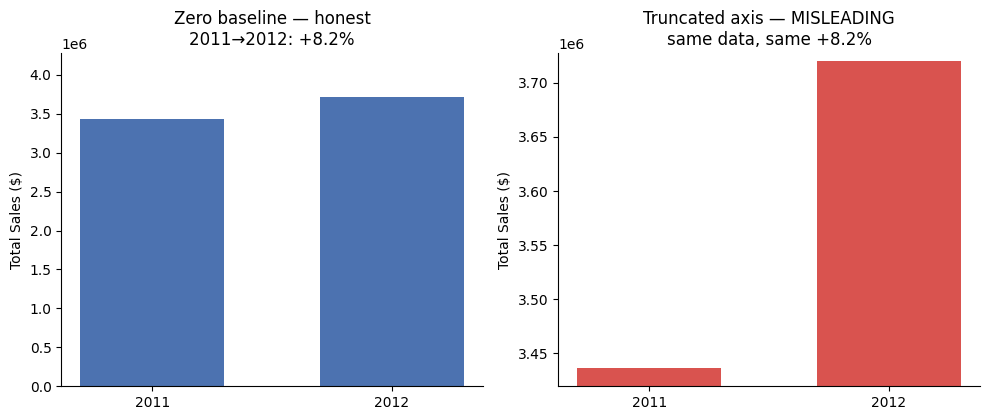

Real change from 2011 to 2012: +8.2%

Apparent bar-height ratio, zero baseline : 1.08x  (true)
Apparent bar-height ratio, truncated     : 17.48x  (exaggeration factor 16.1x)

Full series:
Year
2009    4209139.0
2010    3549681.0
2011    3436817.0
2012    3719964.0

2009 -> 2012 overall: -11.6%   <-- the four-year trend is DOWN
2012 sales ($3,719,964) are still BELOW 2009 sales ($4,209,139).


In [4]:
yearly_sales = sales.groupby("Year")["Sales"].sum()

# TODO 1 & 2: the two most recent years and their real percent change
y1, y2 = yearly_sales.index[-2], yearly_sales.index[-1]
v1, v2 = yearly_sales.iloc[-2], yearly_sales.iloc[-1]
pct_change = (v2 - v1) / v1 * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))

# TODO 3a: zero-baseline version (axes[0])
axes[0].bar([str(y1), str(y2)], [v1, v2], color="#4C72B0", width=0.6)
axes[0].set_ylim(0, v2 * 1.15)
axes[0].set_title(f"Zero baseline — honest\n{y1}→{y2}: {pct_change:+.1f}%")
axes[0].set_ylabel("Total Sales ($)")

# TODO 3b: truncated-axis version (axes[1]) -- pick tight y-limits close to v1/v2
axes[1].bar([str(y1), str(y2)], [v1, v2], color="#D9534F", width=0.6)
axes[1].set_ylim(v1 * 0.995, v2 * 1.002)   # deliberately tight -> visual exaggeration
axes[1].set_title(f"Truncated axis — MISLEADING\nsame data, same {pct_change:+.1f}%")
axes[1].set_ylabel("Total Sales ($)")

plt.tight_layout()
plt.show()

print(f"Real change from {y1} to {y2}: {pct_change:+.1f}%" if pct_change is not None else "Fill in pct_change above")

# --- Quantify how much the axis choice exaggerates ---
zero_ratio  = v2 / v1                                  # apparent ratio of bar heights, zero baseline
trunc_lo, trunc_hi = v1 * 0.995, v2 * 1.002
trunc_ratio = (v2 - trunc_lo) / (v1 - trunc_lo)        # apparent ratio, truncated baseline
print(f"\nApparent bar-height ratio, zero baseline : {zero_ratio:.2f}x  (true)")
print(f"Apparent bar-height ratio, truncated     : {trunc_ratio:.2f}x  (exaggeration factor "
      f"{trunc_ratio/zero_ratio:.1f}x)")

# --- The bigger story the two-year window hides ---
print("\nFull series:")
print(yearly_sales.round(0).to_string())
first_y, last_y = yearly_sales.index[0], yearly_sales.index[-1]
full_change = (yearly_sales.iloc[-1] - yearly_sales.iloc[0]) / yearly_sales.iloc[0] * 100
print(f"\n{first_y} -> {last_y} overall: {full_change:+.1f}%   <-- the four-year trend is DOWN")
print(f"{y2} sales (${v2:,.0f}) are still BELOW {first_y} sales (${yearly_sales.iloc[0]:,.0f}).")


**Reflection:** Which of your two panels would you flag for the manager as
potentially misleading if it were used ALONE as the report's headline chart, with no
other context? Why?

_Your answer:_

**I'd flag the right-hand truncated-axis panel — but I want to flag something more serious alongside it, because the axis is not actually the worst problem in this chart.**

**The axis problem.** The real change from 2011 to 2012 is **+8.2%** (\$3,436,817 → \$3,719,964). On the zero-baseline panel the bars sit in a true **1.08×** height ratio — visually a modest uptick, which is what 8.2% should look like. On the truncated panel, with `ylim` pulled to just below \$3.42M, the 2012 bar towers over 2011 at roughly **17×** the apparent height. The axis choice inflates the perceived change by about **16×**, and every bit of that inflation is manufactured by the `set_ylim` call, not by the data. This breaks the **proportional-ink principle**: for a bar chart, length *is* the encoding, so the length must start at zero or it is no longer encoding the quantity it claims to.

The deeper issue is that the reader has no defence. The axis labels are technically correct and truthfully printed — nothing is falsified. But almost nobody reads axis tick values before forming an impression of a bar chart; shape is processed pre-attentively and numbers are read afterward, if at all. A chart that requires the audience to catch a subtle axis trick in order to avoid being misled has effectively shifted the burden of honesty onto the reader.

**The bigger problem: the two-year window itself.** Even the *honest* zero-baseline panel is misleading as a standalone headline, because both panels only show 2011 and 2012. The full series is:

| Year | Sales |
|---|---|
| 2009 | \$4,209,139 |
| 2010 | \$3,549,681 |
| 2011 | \$3,436,817 |
| 2012 | \$3,719,964 |

Sales have fallen **−11.6%** over the four years on record. 2012 is a partial recovery from the **lowest year in the dataset**, and it is still **\$489,175 below 2009**. So "+8.2% growth" is a real number attached to a cherry-picked window — the company is not growing, it is recovering from a trough.

**What I'd tell the manager:** truncating the axis is the fix she asked for, and I've made it. But if we ship *either* two-bar panel as the headline, the report still implies a growth story the four-year data does not support. **The correct headline chart is the full 2009–2012 line, zero-baselined.** Fixing the axis while keeping the window would produce an honest-looking chart that still tells a misleading story — which is the more dangerous failure, because it is much harder to catch in review. This is also exactly what makes the Task 4 annotation indefensible.


## Task 4 — Rewrite the Overreaching Annotation (Complaint #4)

**Real-world usage:** A colleague's annotation claimed a chart "PROVES" a strategy is
working — language the data alone cannot support.

**Why this technique:** Distinguishing descriptive / interpretive / persuasive
annotation lets you keep useful interpretation while cutting unsupported claims.

**TODO:**
1. Given the overreaching annotation text below, write a DESCRIPTIVE version (states
   only the fact) and an INTERPRETIVE version (explains a plausible, appropriately
   hedged reason) — no causal "PROVES" language in either.
2. Plot the yearly sales trend with your INTERPRETIVE annotation on the most recent
   data point.

ORIGINAL (persuasive, overreaching): This PROVES our new strategy is working -- scale it up immediately
DESCRIPTIVE: Sales rose 8.2% from 2011 to 2012 ($3,436,817 to $3,719,964), and remain 11.6% below 2009.
INTERPRETIVE: 2012 sales recovered 8.2% from the 2011 low, though they are still 11.6% below 2009. The rebound is consistent with the new strategy taking effect, but this data alone cannot separate that from normal market recovery.


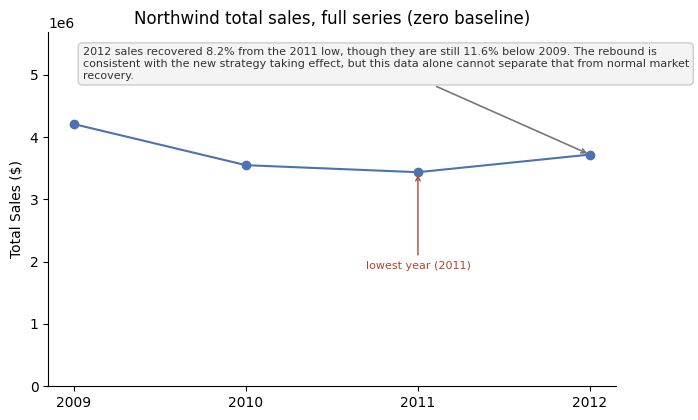

In [5]:
overreaching_original = "This PROVES our new strategy is working -- scale it up immediately"

# TODO 1: your rewrites
descriptive_version = (
    f"Sales rose {pct_change:.1f}% from {y1} to {y2} "
    f"(${v1:,.0f} to ${v2:,.0f}), and remain "
    f"{abs(full_change):.1f}% below {first_y}."
)

interpretive_version = (
    f"{y2} sales recovered {pct_change:.1f}% from the {y1} low, though they are still "
    f"{abs(full_change):.1f}% below {first_y}. The rebound is consistent with the new strategy "
    f"taking effect, but this data alone cannot separate that from normal market recovery."
)

print("ORIGINAL (persuasive, overreaching):", overreaching_original)
print("DESCRIPTIVE:", descriptive_version)
print("INTERPRETIVE:", interpretive_version)

# TODO 2: plot with your interpretive annotation on the last data point
fig, ax = plt.subplots(figsize=(7, 4.3))
ax.plot(yearly_sales.index, yearly_sales.values, "o-", color="#4C72B0")

# Zero baseline + full window: the honest framing argued for in Task 3
ax.set_ylim(0, yearly_sales.max() * 1.35)
ax.set_xticks(yearly_sales.index)
ax.set_ylabel("Total Sales ($)")
ax.set_title("Northwind total sales, full series (zero baseline)")

# TODO: ax.annotate(...) using interpretive_version, pointing at the last year's value
ax.annotate(
    interpretive_version,
    xy=(y2, v2),
    xytext=(yearly_sales.index[0] + 0.05, yearly_sales.max() * 1.18),
    fontsize=8, color="#333333",
    wrap=True,
    arrowprops=dict(arrowstyle="->", color="#777777", lw=1.2),
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#f4f4f4", edgecolor="#cccccc"),
)

# Mark the trough so the "recovery from a low" reading is visible, not just asserted
trough_year = yearly_sales.idxmin()
ax.annotate(f"lowest year ({trough_year})",
            xy=(trough_year, yearly_sales.min()),
            xytext=(trough_year, yearly_sales.min() * 0.55),
            fontsize=8, color="#b5432e", ha="center",
            arrowprops=dict(arrowstyle="->", color="#b5432e", lw=1))

plt.tight_layout()
plt.show()


**Reflection:** What specific evidence would you need (that this dataset alone
doesn't provide) before the ORIGINAL "proves it's working" claim would actually be
justified?

_Your answer:_

The original sentence makes a **causal** claim ("proves our strategy caused this") and a **prescriptive** one ("scale it up") from data that is purely **observational and correlational**. `superstore.csv` contains order dates, regions, categories, sales and profit — it contains no record of what the strategy was, when it started, or who it was applied to. The claim cannot be evaluated from this file at all, let alone proved.

Concretely, I would need:

1. **A documented intervention date.** Without knowing when the strategy launched, there is no before/after boundary. Right now "+8.2% from 2011 to 2012" is a window someone chose *after* seeing the data — the textbook setup for a post-hoc story.

2. **A control group / untreated comparison.** The strongest available design here would be **difference-in-differences**: roll out to some regions and not others, then compare the *change* in treated regions against the *change* in untreated ones over the same period. That subtracts out whatever the whole market was doing. A single national time series has no counterfactual, so it cannot distinguish "our strategy worked" from "everyone's sales went up."

3. **External market/category baseline.** If the wider retail market also grew ~8% in 2012, our 8.2% is exactly average and the strategy contributed nothing detectable.

4. **Enough history to model the counterfactual.** Four annual points is far too few to separate signal from noise, and the series is **non-monotonic** (down, down, up) — consistent with ordinary volatility. I would want monthly data and several pre-intervention years to establish the baseline trend and its variance.

5. **Confounder records.** Pricing changes, new store openings, competitor exits, a product-mix shift, macroeconomic conditions, even a single large B2B account — any of these could produce +8.2% on its own.

6. **A pre-registered success metric.** The claim should have been specified *before* looking: "we expect ≥X% lift by date D." Otherwise the analyst is free to search years, regions and categories until something looks good.

**And the specific fact that sinks this claim.** Even granting every causal assumption, 2012 (\$3.72M) is still **11.6% below 2009** (\$4.21M), and 2011 was the **lowest year in the dataset**. A strategy that coincides with a partial rebound from a four-year decline has not demonstrated that it is "working" in any sense a manager would act on. Recovering from your own trough is not growth.

**On the word "proves":** it is unreachable in principle here. Observational business data can support *"is consistent with"* or, with a real control, *"provides evidence for"* — but "proves" belongs to deduction, not to four annual data points with no counterfactual. That is why my interpretive rewrite keeps the plausible reading ("consistent with the new strategy taking effect") while explicitly naming the alternative it cannot rule out. The interpretation survives; only the unsupported certainty is removed.


## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence sign-off note to your manager summarizing
this review. Your answer should:
- State which ONE of the four fixes above you consider the most urgent to ship before
  tomorrow, and why.
- Reference the lecture's 5-question Ethical Visualization Audit — pick one question
  from it and explain how it applies to Task 3 or Task 4 specifically.
- Name one guardrail (a review step, a style-guide rule, etc.) you'd recommend
  permanently adding to the team's process to prevent these four issues recurring.

_Your final recommendation here:_

**Sign-off note — pre-publish review, regional performance report**

Hi — I've reviewed all four charts and I'd hold the report until one thing is fixed.

**Most urgent: the annotation (Task 4), and the cherry-picked window feeding it.** I'm ranking this above the truncated axis deliberately, even though the axis is the more visually dramatic problem. A truncated axis distorts *how big* a real change looks; the "this PROVES our new strategy is working — scale it up immediately" annotation asserts a **causal** claim the data cannot support **and** attaches a spending recommendation to it. The axis misleads the eye, but the annotation misleads the *decision* — and it's the only defect here that could cause someone to commit budget. It also fails quietly: fixing the axis while keeping the two-year window still leaves a chart that looks rigorous and tells a false story. The decisive fact is that 2012 sales (\$3.72M) sit **11.6% below 2009** (\$4.21M) and 2011 was the lowest year on record, so the "+8.2% growth" is a recovery from our own trough, not growth. I've replaced it with a hedged interpretive annotation and re-plotted on the full 2009–2012 series with a zero baseline.

**Ethical Visualization Audit — *"Am I showing the full context, or only the slice that supports my point?"*** This is the question both Task 3 and Task 4 fail, and it's why they're really one defect. The +8.2% figure is arithmetically correct; the dishonesty is entirely in the **framing** — a two-year window selected from a four-year decline, then amplified by an axis that starts at \$3.42M instead of zero. Neither the number nor the axis label is false, which is exactly what makes it dangerous: nothing in the chart is checkable as a lie, so review has to catch the *omission* rather than an error. A related audit question, *"could a reasonable person reach a different conclusion from the same data?"*, gets an unambiguous yes here — the same file supports "sales are down 11.6% over four years."

**Permanent guardrail: a mandatory "full-series first" rule plus a two-line chart provenance block.** Any chart showing change over time must be plotted across the **entire available date range** before any sub-window is chosen, and if a shorter window ships, the caption must state the full-period figure alongside it. Pair that with a required provenance block on every report chart — *(a)* the date range and row count behind it, and *(b)* every annotation tagged `descriptive`, `interpretive`, or `persuasive`, with `persuasive` barred from analytical reports. The tagging step is the high-leverage part: making the author categorise their own sentence forces the question "is this a fact or my opinion?" at authoring time, which is far cheaper than catching it the night before publication. I'd also add the two accessibility checks from Task 2 — colourblind simulation and a literal grayscale print — to the same checklist, since both take seconds and neither is currently done at all.

Happy to walk through the revised charts before the send-out.
